# Домашнее задание 3. Логистическая регрессия и Streamlit

симонов алексей дмитриевич, БПИ248

## Описание

В этом задании вы реализуете логистическую регрессию своими руками, разберётесь с метриками качества классификации на реальных несбалансированных данных и упакуете итоговую модель в интерактивное веб-приложение на Streamlit.

- Первая часть посвящена реализации логистической регрессии с помощью градиентного и стохастического градиентного спуска.
- Вторая часть посвящена метрикам классификации: матрице ошибок, precision, recall, $F_\beta$, ROC- и PR-кривым, выбору порога.
- Третья часть посвящена работе с несбалансированными классами.
- Четвертая часть посвящена созданию демонстрации на Streamlit.

**Максимальный балл за задание: 10** (по 2.5 балла за каждую из четырёх частей).

## Общие требования к ДЗ-3

- Для каждого задания приведите код решения.
- Там, где требуется интерпретация, добавьте короткий текстовый вывод.
- Следите за тем, чтобы ноутбук выполнялся последовательно сверху вниз.
- Везде, где есть случайность, фиксируйте `random_state=42`.
- Тестовая выборка используется **только** для финальной оценки качества. Всё, что «подбирается» (гиперпараметры, порог, ресемплинг, параметры масштабирования), подбирается по тренировочной выборке.

> В каждой части оцениваются как код, так и ответы на вопросы. Если отсутствует одно из двух, часть баллов за соответствующее задание может быть снижена.

**Использование LLM:** при выполнении работы использовался ChatGPT для помощи с написанием (дебажить ошибки) и проверкой кода и написания сайта


In [1]:
%pip install -q numpy==2.5.4 pandas==3.1.1 matplotlib==3.11.2 seaborn==0.13.2 scikit-learn==1.9.1 imbalanced-learn==0.14.2 joblib==1.6.0


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: /Users/adsimyandex/Documents/ChatGPT/вышка/HW3_MMDA/.venv/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

sns.set_style('darkgrid')
RANDOM_STATE = 42
from pathlib import Path
from sklearn.base import clone
from IPython.display import display

## <font color="green">Часть 1. Логистическая регрессия своими руками (2.5 балла)</font>

На лекции мы получили функцию потерь логистической регрессии из метода максимума правдоподобия. Если $p_i = \sigma(\langle w, x_i \rangle)$ – предсказанная вероятность класса 1 для $i$-го объекта, то

$$Q(w) = -\frac{1}{\ell}\sum_{i=1}^{\ell}\Big(y_i \log p_i + (1 - y_i)\log(1 - p_i)\Big) \to \min_w, \qquad \sigma(z) = \frac{1}{1 + e^{-z}}.$$

Явной формулы для минимума, как у МНК, здесь нет, поэтому веса ищем градиентным спуском – так же, как на семинаре 3 для линейной регрессии.

**Подсказка.** Сначала выведите градиент $\nabla Q(w)$ на бумаге и запишите его в матричном виде через $X$, $y$ и вектор вероятностей $p$. Вывод градиента приводить в ноутбуке не обязательно, но на защите его могут попросить.

### Задание 1.1. Класс `LogReg` (1.5 балла)

Реализуйте класс логистической регрессии, обучаемой с помощью:
- **полного градиентного спуска** – `gd_type='full'` (1 балл);
- **стохастического градиентного спуска** – `gd_type='stochastic'`: на каждой итерации градиент оценивается по случайному батчу из `batch_size` объектов, как в функции `calc_grad_on_batch` с семинара 3 (0.5 балла).

**Требования:**
- Градиентный спуск записан в векторном виде. Циклы средствами Python допускаются **только** по итерациям градиентного спуска.
- Свободный член $w_0$ учитывается так, как на лекции: внутри `fit` и `predict_proba` к матрице признаков добавляется фиктивный признак $x_0 = 1$ (первым столбцом). Таким образом, `self.w` имеет размер `d + 1`, и `self.w[0]` – это свободный член.
- Критерии остановки (одновременно):
  - L2 норма разности весов на двух соседних итерациях меньше `tolerance`;
  - достигнуто максимальное число итераций `max_iter`.
- Атрибут `loss_history` после вызова `fit` содержит значение функции потерь **на всей обучающей выборке** для каждой итерации, начиная с первой (до совершения первого шага по антиградиенту).
- Веса инициализируются вектором `w0`, если он передан, иначе – нулевым вектором.
- `predict_proba` возвращает массив размера `(N, 2)`: в первом столбце вероятность класса 0, во втором – класса 1 (как в `sklearn`).
- `predict` возвращает метки классов `0/1`, сравнивая вероятность класса 1 с порогом `threshold`.
- При вычислении логарифма в `calc_loss` позаботьтесь о вычислительной устойчивости: $\log 0$ давать не должно (например, используйте `np.clip`).

Полезно [почитать](https://scikit-learn.org/stable/developers/develop.html) о том, как устроены модели в `sklearn`.

**ВАЖНО!** Заполните шаблон ниже, не меняя структуру класса и сигнатуры методов. Добавлять свои вспомогательные методы можно.

In [3]:
class LogReg(BaseEstimator, ClassifierMixin):
    def __init__(self, gd_type='full', tolerance=1e-4, max_iter=1000,
                 w0=None, eta=1e-2, batch_size=32, random_state=42):
        """
        gd_type: 'full' или 'stochastic'
        tolerance: порог для критерия останова по норме разности весов
        max_iter: максимальное число итераций градиентного спуска
        w0: np.array размера (d + 1) — начальные веса (w0[0] — свободный член)
        eta: длина шага (learning rate)
        batch_size: размер батча для стохастического градиентного спуска
        random_state: seed для выбора батчей
        """
        self.gd_type = gd_type
        self.tolerance = tolerance
        self.max_iter = max_iter
        self.w0 = w0
        self.eta = eta
        self.batch_size = batch_size
        self.random_state = random_state

    def fit(self, X, y):
        """
        X: np.array размера (N, d)
        y: np.array размера (N) из 0 и 1
        ---
        output: self
        """
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        self.classes_ = np.array([0, 1])
        self.loss_history = []
        rng = np.random.default_rng(self.random_state)


        self.n_features_in_ = X.shape[1]
        X = np.column_stack((np.ones(X.shape[0]), X))
        self.w = (np.zeros(X.shape[1]) if self.w0 is None
                else np.asarray(self.w0, dtype=float).copy())
        self.n_iter_ = 0
        self.stop_reason_ = 'max_iter'



        for iteration in range(self.max_iter):
            self.loss_history.append(self.calc_loss(X, y))
            if self.gd_type == 'full':
                gradient = self.calc_gradient(X, y)
            elif self.gd_type == 'stochastic':
                batch = rng.choice(X.shape[0], size=self.batch_size, replace=False)
                gradient = self.calc_gradient(X[batch], y[batch])
            else:
                raise ValueError("gd_type must be 'full' or 'stochastic'")


            new_w = self.w - self.eta * gradient
            step_norm = np.linalg.norm(new_w - self.w)
            self.w = new_w
            self.n_iter_ = iteration + 1
            if step_norm < self.tolerance:
                self.stop_reason_ = 'tolerance'
                break

        return self

    def sigmoid(self, z):
        z = np.asarray(z, dtype=float)
        return np.exp(-np.logaddexp(0, -z))

    def predict_proba(self, X):
        """
        X: np.array размера (N, d)
        ---
        output: np.array размера (N, 2)
        """
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')

        X = np.asarray(X, dtype=float)
        X = np.column_stack((np.ones(X.shape[0]), X))

        p = self.sigmoid(X @ self.w)
        return np.column_stack((1 - p, p))

    def predict(self, X, threshold=0.5):
        """
        X: np.array размера (N, d)
        ---
        output: np.array размера (N) из 0 и 1
        """
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')

        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

    def calc_gradient(self, X, y):
        """
        X: np.array размера (N, d + 1) — уже с фиктивным признаком
           (N может быть равно batch_size при стохастическом спуске)
        y: np.array размера (N)
        ---
        output: np.array размера (d + 1) — градиент log-loss по self.w
        """
        return X.T @ (self.sigmoid(X @ self.w) - y) / X.shape[0]

    def calc_loss(self, X, y):
        """
        X: np.array размера (N, d + 1) — уже с фиктивным признаком
        y: np.array размера (N)
        ---
        output: float — значение log-loss при текущих self.w
        """
        z = X @ self.w
        return float(np.mean(np.logaddexp(0, (1 - 2 * y) * z)))

Ячейка ниже проверяет вашу реализацию градиента численно: сравнивает `calc_gradient` с конечными разностями функции `calc_loss`. Она не оценивается, но если проверка не проходит – ищите ошибку, прежде чем идти дальше.

In [4]:
def check_gradient(model, d=5, N=50, eps=1e-6, seed=42):
    rng = np.random.default_rng(seed)
    X = np.hstack([np.ones((N, 1)), rng.normal(size=(N, d))])
    y = rng.integers(0, 2, size=N).astype(float)
    model.w = rng.normal(size=d + 1)

    analytic = model.calc_gradient(X, y)
    numeric = np.zeros(d + 1)
    w = model.w.copy()
    for j in range(d + 1):
        e = np.zeros(d + 1)
        e[j] = eps
        model.w = w + e
        loss_plus = model.calc_loss(X, y)
        model.w = w - e
        loss_minus = model.calc_loss(X, y)
        numeric[j] = (loss_plus - loss_minus) / (2 * eps)
    model.w = w
    return np.max(np.abs(analytic - numeric))


err = check_gradient(LogReg())
print(f'max |analytic - numeric| = {err:.2e}')
assert err < 1e-5, 'Градиент не совпадает с численным — проверьте calc_gradient и calc_loss'

max |analytic - numeric| = 2.49e-10


Теперь проверим работу класса на синтетических данных.

In [5]:
X, y = make_classification(
    n_samples=20000, n_features=20, n_informative=5,
    random_state=RANDOM_STATE)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

### Задание 1.2. Обучение и сходимость (0.25 балла)

1. Обучите две модели: `LogReg(gd_type='full')` и `LogReg(gd_type='stochastic')` с параметрами по умолчанию.
2. Для каждой модели выведите число сделанных итераций и постройте на одном графике `loss_history` обеих моделей.
3. Ответьте на вопросы:
   - По какому критерию остановилась каждая модель – по `tolerance` или по `max_iter`?
   - Почему стохастическому спуску с постоянным шагом трудно остановиться по критерию `tolerance`?
   - Чем отличаются графики функции потерь?
   - Сколько объектов «просматривает» за одну итерацию каждый из методов?

,модель,итерации,остановка
0,gd,1000,max_iter
1,sgd,1000,max_iter


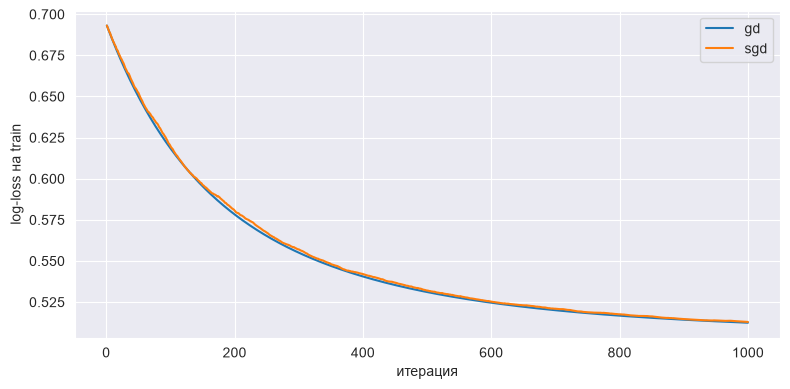

In [6]:
synth_gd = LogReg(gd_type='full').fit(X_train, y_train)
synth_sgd = LogReg(gd_type='stochastic').fit(X_train, y_train)
synth_models = {'gd': synth_gd, 'sgd': synth_sgd}


display(pd.DataFrame([
   {'модель': name, 'итерации': model.n_iter_, 'остановка': model.stop_reason_}
  for name, model in synth_models.items()
]))



plt.figure(figsize=(8, 4))
for name, model in synth_models.items():
    plt.plot(np.arange(1, model.n_iter_ + 1), model.loss_history, label=name)

plt.xlabel('итерация')
plt.ylabel('log-loss на train')
plt.legend()
plt.tight_layout()
plt.show()

обе модели сделали по 1000 итераций и остановились по max_iter. до tolerance при настройках по умолчанию они не дошли

у gd loss снижается плавно. у sgd кривая более шумная: на каждом шаге берется новый случайный батч. с постоянным шагом шум остается даже около минимума, поэтому разность соседних весов не обязательно становится меньше tolerance

для градиента gd использует все 14000 объектов train, а sgd только 32. но по условию loss на каждом шаге считается на всей выборке у обеих моделей, поэтому стоимость полной итерации sgd здесь тоже зависит от размера train

### Задание 1.3. Длина шага (0.25 балла)

Для полного градиентного спуска обучите модели с сеткой `eta` из списка `[1e-3, 1e-2, 1e-1, 1, 10]` и постройте графики `loss_history` (удобно в логарифмической шкале по оси `x`). Выведите для каждого `eta` финальное значение функции потерь и число итераций.

Как длина шага влияет на скорость и качество сходимости? Есть ли значения `eta`, при которых спуск ведёт себя плохо?

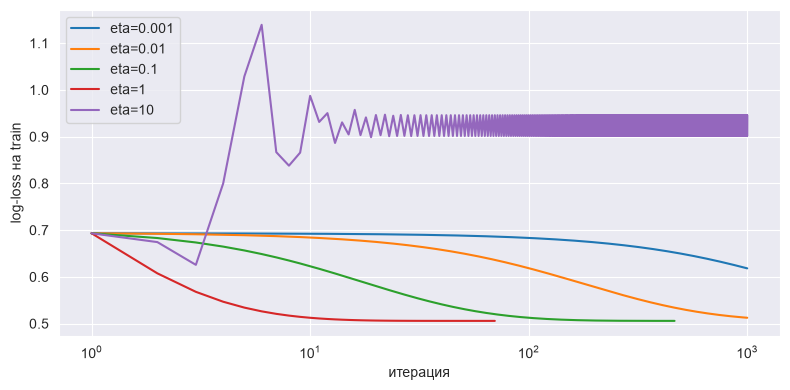

,eta,финальный log-loss,итерации,остановка
0,0.001,0.618087,1000,max_iter
1,0.010,0.512435,1000,max_iter
2,0.100,0.505762,465,tolerance
3,1.000,0.505757,70,tolerance
4,10.000,0.901345,1000,max_iter


In [7]:
synth_eta_rows = []
synth_eta_models = {}
synth_X_train_bias = np.column_stack((np.ones(X_train.shape[0]), X_train))


plt.figure(figsize=(8, 4))
for eta in [1e-3, 1e-2, 1e-1, 1, 10]:
    model = LogReg(gd_type='full', eta=eta).fit(X_train, y_train)
    synth_eta_models[eta] = model
    synth_eta_rows.append({
       'eta': eta,
         'финальный log-loss': model.calc_loss(synth_X_train_bias, y_train),
       'итерации': model.n_iter_,
        'остановка': model.stop_reason_,
    })
    plt.plot(np.arange(1, model.n_iter_ + 1), model.loss_history, label=f'eta={eta:g}')


plt.xscale('log')
plt.xlabel('итерация')
plt.ylabel('log-loss на train')
plt.legend()
plt.tight_layout()
plt.show()

display(pd.DataFrame(synth_eta_rows))

при eta=0.001 за 1000 итераций loss снизился только до 0.6181, при eta=0.01 - до 0.5124. маленький шаг работает, но сходится медленно

при eta=0.1 остановка по tolerance произошла за 465 итераций, при eta=1 - за 70. в обоих случаях loss примерно 0.5058. eta=10 оказался слишком большим: loss колеблется и в конце равен 0.9013, критерий tolerance не выполнен

больший шаг ускоряет сходимость только до некоторого предела. финальный loss в таблице вычислен после последнего обновления весов, а последний элемент loss_history относится к состоянию перед ним

### Задание 1.4. Сравнение с `sklearn` (0.5 балла)

1. Обучите `LogisticRegression` из `sklearn` с параметрами по умолчанию.
2. Для трёх моделей (ваш GD, ваш SGD, `sklearn`) посчитайте на тестовой выборке accuracy и ROC-AUC и сведите их в таблицу `pd.DataFrame`.
3. Сравните веса вашей модели (GD) с весами модели `sklearn` (`intercept_` и `coef_`).

Ответьте на вопросы:
   - Совпадают ли метрики? Совпадают ли веса?
   - Что в модели `sklearn` по умолчанию делает её не равной вашей? Найдите ответ в [документации](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html). Как настроить `LogisticRegression`, чтобы она решала ту же задачу оптимизации, что и ваша модель?

In [8]:
synth_sklearn = LogisticRegression(random_state=RANDOM_STATE).fit(X_train, y_train)
synth_comparison = {**synth_models, 'sklearn': synth_sklearn}



synth_metric_table = pd.DataFrame([
  {
     'модель': name,
    'accuracy': metrics.accuracy_score(y_test, model.predict(X_test)),
     'roc_auc': metrics.roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]),
   }
  for name, model in synth_comparison.items()
])

display(synth_metric_table)


synth_sklearn_weights = np.r_[synth_sklearn.intercept_, synth_sklearn.coef_.ravel()]
synth_weight_table = pd.DataFrame({
   'gd': synth_gd.w,
    'sklearn': synth_sklearn_weights,
     'разность': synth_gd.w - synth_sklearn_weights,
}, index=['intercept'] + [f'x{i}' for i in range(X_train.shape[1])])


display(synth_weight_table)
print('l2 нормы разности весов:', np.linalg.norm(synth_gd.w - synth_sklearn_weights))

,модель,accuracy,roc_auc
0,gd,0.7820,0.838787
1,sgd,0.7825,0.838115
2,sklearn,0.7765,0.838676


,gd,sklearn,разность
intercept,-0.002114,-0.021880,0.019765
x0,0.006076,0.002741,0.003335
x1,0.006963,0.009039,-0.002077
x2,-0.547170,-0.722690,0.175520
x3,-0.144536,-0.262335,0.117799
x4,0.012487,0.016588,-0.004102
x5,-0.006325,-0.011488,0.005163
x6,0.000814,0.005587,-0.004773
x7,0.039084,0.057188,-0.018104
x8,-0.002425,-0.001239,-0.001185


l2 нормы разности весов: 0.35678325060907684


метрики близкие, но не одинаковые. accuracy у gd, sgd и sklearn равны 0.7820, 0.7825 и 0.7765, roc-auc - примерно 0.8388, 0.8381 и 0.8387. веса тоже отличаются: l2-норма разности весов gd и sklearn равна 0.3568

наш gd с настройками по умолчанию остановился по лимиту итераций, а не по сходимости. кроме того, у sklearn по умолчанию есть l2-регуляризация, которой нет в нашем классе. это меняет саму задачу оптимизации. алгоритмы и критерии остановки также различаются

чтобы решать ту же задачу без регуляризации в sklearn 1.9, можно задать `LogisticRegression(C=np.inf, tol=1e-8, max_iter=10000)`. собственному gd тоже нужно дать сойтись точнее. совпадение весов до последнего знака не требуется, особенно при линейно зависимых признаках. параметры описаны в [документации](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)

## <font color="green">Часть 2. Метрики классификации (2.5 балла)</font>

### Данные

Используем датасет [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality) (P. Cortez et al., 2009, лицензия CC BY 4.0).
Каждая строка – образец португальского вина: 11 физико-химических характеристик и признак `is_red` (1 - красное, 0 - белое). Эксперты оценили каждое вино по шкале от 0 до 10. Мы превратили оценку в бинарную целевую переменную:

- `target = 1` – «хорошее» вино (оценка не ниже 7);
- `target = 0` – все остальные.

**Сценарий.** Сервис по подписке каждый месяц рекомендует клиентам вина. Модель должна по результатам лабораторного анализа отбирать «хорошие» вина в подборку. Рекомендовать клиенту посредственное вино — плохо (клиент разочаруется), но и пропускать хорошие вина тоже не хочется (подборка получится скудной).

In [9]:
data_url = 'https://raw.githubusercontent.com/paiflare/ml_hse_2026/refs/heads/master/homework/hw_3/Data/wine_quality.csv'
data_path = Path('wine_quality.csv')
df_raw = pd.read_csv(data_path if data_path.exists() else data_url)


print('исходный размер:', df_raw.shape)
print('пропуски:', df_raw.isna().sum().sum())
print('полные дубликаты:', df_raw.duplicated().sum())



# удаляем до split, чтобы одна запись не попала в обе выборки
df = df_raw.drop_duplicates().reset_index(drop=True)

print('после удаления дубликатов:', df.shape)
df.head()

исходный размер: (6497, 13)
пропуски: 0
полные дубликаты: 1177
после удаления дубликатов: (5320, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,is_red,target
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,1,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,1,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,1,0
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,1,0


In [10]:
X = df.drop(columns='target')
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (3724, 12)  Test: (1596, 12)


### Задание 2.1. Первичный анализ и accuracy (0.25 балла)

1. Проверьте данные на пропуски и полные дубликаты строк. Нужно ли удалять дубликаты в этой задаче? Посчитайте долю класса 1 (prevalence) в тренировочной и тестовой выборках. Зачем при разбиении был указан параметр `stratify=y`?
2. Посчитайте accuracy на тестовой выборке для константной модели, которая всегда отвечает «не хорошее вино» (класс 0).
3. Обучите пайплайн `make_pipeline(StandardScaler(), LogisticRegression())` и посчитайте его accuracy на тестовой выборке.

Сравните два числа. Почему accuracy плохо подходит для этой задачи?

In [11]:
print('пропуски по столбцам:')
display(df_raw.isna().sum().to_frame('число пропусков'))
print('дубликаты до очистки:', df_raw.duplicated().sum())
print('дубликаты после очистки:', df.duplicated().sum())

display(pd.DataFrame({
   'выборка': ['train', 'test'],
     'объекты': [len(y_train), len(y_test)],
    'доля класса 1': [y_train.mean(), y_test.mean()],
}))



def evaluate(model, X_eval, y_eval, threshold=0.5):
    proba = model.predict_proba(X_eval)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {
        'accuracy': metrics.accuracy_score(y_eval, pred),
       'precision': metrics.precision_score(y_eval, pred, zero_division=0),
        'recall': metrics.recall_score(y_eval, pred, zero_division=0),
         'f1': metrics.f1_score(y_eval, pred, zero_division=0),
        'roc_auc': metrics.roc_auc_score(y_eval, proba),
        'pr_auc': metrics.average_precision_score(y_eval, proba),
    }


wine_lr = make_pipeline(StandardScaler(), LogisticRegression(random_state=RANDOM_STATE))
wine_lr.fit(X_train, y_train)

constant_accuracy = metrics.accuracy_score(y_test, np.zeros(len(y_test), dtype=int))
lr_accuracy = metrics.accuracy_score(y_test, wine_lr.predict(X_test))
display(pd.DataFrame({
    'модель': ['всегда 0', 'логистическая регрессия'],
    'accuracy': [constant_accuracy, lr_accuracy],
}))

пропуски по столбцам:


,число пропусков
fixed_acidity,0
volatile_acidity,0
citric_acid,0
residual_sugar,0
chlorides,0
free_sulfur_dioxide,0
total_sulfur_dioxide,0
density,0
pH,0
sulphates,0


дубликаты до очистки: 1177
дубликаты после очистки: 0


,выборка,объекты,доля класса 1
0,train,3724,0.189581
1,test,1596,0.189850


,модель,accuracy
0,всегда 0,0.810150
1,логистическая регрессия,0.815163


пропусков нет. из 6497 строк 1177 являются полными дубликатами, после удаления осталось 5320. для оценки на новых винах я убрал дубликаты до разбиения: иначе одна запись могла оказаться и в train, и в test. без идентификатора образца нельзя точно установить, были ли это повторные измерения или повторные записи

доля хороших вин в train равна 0.1896, в test - 0.1898. stratify=y сохраняет примерно одинаковые доли классов при разбиении

accuracy константной модели равна 0.8102, логистической регрессии - 0.8152. разница всего около 0.5 процентного пункта, хотя константная модель вообще не находит хорошие вина. accuracy сильно зависит от большинства, поэтому здесь нужны precision, recall и f-меры

### Задание 2.2. Матрица ошибок своими руками (0.5 балла)

Для пайплайна логистической регрессии из задания 2.1 получите предсказания классов на тестовой выборке.

1. Посчитайте TP, TN, FP, FN **без функций из `sklearn.metrics`** – только средствами `numpy`/`pandas`.
2. Сравните результат с `metrics.confusion_matrix` и нарисуйте матрицу ошибок с помощью `metrics.ConfusionMatrixDisplay`.
3. Объясните в терминах сценария, что означают FP и FN в этой задаче. Какая из ошибок модели встречается чаще?

TP=92, TN=1209, FP=84, FN=211


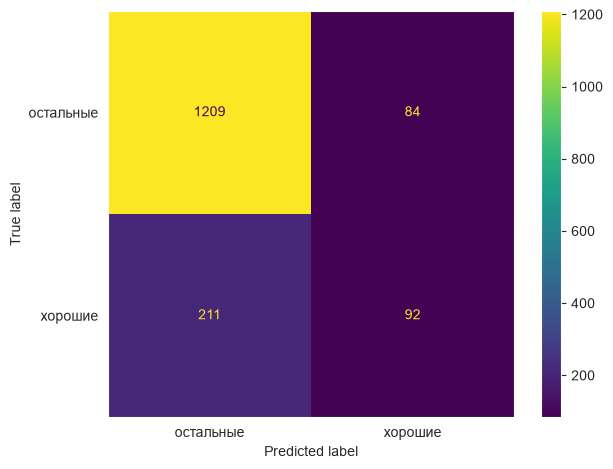

In [12]:
y_pred = wine_lr.predict(X_test)
truth = y_test.to_numpy()

TP = np.sum((truth == 1) & (y_pred == 1))
TN = np.sum((truth == 0) & (y_pred == 0))
FP = np.sum((truth == 0) & (y_pred == 1))
FN = np.sum((truth == 1) & (y_pred == 0))


manual_cm = np.array([[TN, FP], [FN, TP]])
print(f'TP={TP}, TN={TN}, FP={FP}, FN={FN}')
assert np.array_equal(manual_cm, metrics.confusion_matrix(y_test, y_pred))



cm_display = metrics.ConfusionMatrixDisplay(
   manual_cm, display_labels=['остальные', 'хорошие'],
).plot()
cm_display.ax_.grid(False)
plt.tight_layout()
plt.show()

получилось TP=92, TN=1209, FP=84, FN=211. ручная матрица полностью совпала со sklearn

FP означает, что в подборку попало вино с оценкой ниже 7. FN означает, что хорошее вино не попало в подборку. чаще встречается FN: модель пропустила 211 хороших вин и ошибочно порекомендовала 84 остальных

### Задание 2.3. Precision, recall, $F_\beta$ (0.5 балла)

1. Используя TP, TN, FP, FN из задания 2.2, посчитайте по формулам precision, recall, $F_1$, $F_{0.5}$ и $F_2$:

$$F_{\beta} = (1 + \beta^2)\frac{\text{Precision} \cdot \text{Recall}}{\beta^2 \cdot \text{Precision} + \text{Recall}}.$$

2. Проверьте свои значения с помощью `metrics.precision_score`, `metrics.recall_score`, `metrics.fbeta_score`.
3. Ответьте на вопросы:
   - Что больше ценится в $F_{0.5}$, а что в $F_2$ – precision или recall?
   - Какую из трёх F-мер вы бы выбрали для нашего сценария, если подписчики очень болезненно реагируют на посредственные вина в подборке? А если сервис позиционирует себя как «самая широкая подборка хороших вин»?

In [13]:
precision_manual = TP / (TP + FP)
recall_manual = TP / (TP + FN)
fbeta_rows = []

for beta in [0.5, 1, 2]:
    value = ((1 + beta ** 2) * precision_manual * recall_manual
          / (beta ** 2 * precision_manual + recall_manual))
    reference = metrics.fbeta_score(y_test, y_pred, beta=beta)
    fbeta_rows.append({'beta': beta, 'по формуле': value, 'sklearn': reference})


assert np.isclose(precision_manual, metrics.precision_score(y_test, y_pred))
assert np.isclose(recall_manual, metrics.recall_score(y_test, y_pred))
assert np.allclose([row['по формуле'] for row in fbeta_rows],
                [row['sklearn'] for row in fbeta_rows])



print('precision:', precision_manual, 'recall:', recall_manual)
display(pd.DataFrame(fbeta_rows))

precision: 0.5227272727272727 recall: 0.30363036303630364


,beta,по формуле,sklearn
0,0.5,0.456802,0.456802
1,1.0,0.384134,0.384134
2,2.0,0.331412,0.331412


precision равен 0.5227, recall - 0.3036. примерно половина рекомендованных вин хорошие, но модель находит только около 30% всех хороших вин

получились f1=0.3841, f0.5=0.4568 и f2=0.3314. ручные значения совпали со sklearn

f0.5 сильнее учитывает precision, f2 - recall. если подписчики болезненно реагируют на посредственные вина, я выберу f0.5. если сервис обещает самую широкую подборку хороших вин, подойдет f2. f1 дает равный вес precision и recall

### Задание 2.4. ROC- и PR-кривые (0.5 балла)

Сравним две модели:
- `make_pipeline(StandardScaler(), LogisticRegression())` из `sklearn`;
- ваш `LogReg(gd_type='full')` из части 1 (не забудьте масштабировать признаки, подберите `eta` и `max_iter` так, чтобы спуск сошёлся).

1. Для каждой модели получите на тестовой выборке **непрерывные оценки** (score) – вероятность класса 1.
2. Постройте ROC-кривые двух моделей на одном графике и PR-кривые двух моделей на другом графике. На PR-графике отметьте горизонтальной линией уровень случайной модели.
3. Посчитайте ROC-AUC (`metrics.roc_auc_score`) и PR-AUC (`metrics.average_precision_score`) и сведите в таблицу.
4. Возьмите вероятности $p$ класса 1 модели из `sklearn` и посчитайте ROC-AUC для преобразованных оценок: $10 \cdot p$, $p^3$, $\log\frac{p}{1-p}$, $-p$. Объясните результат.

Ответьте на вопросы:
- Какая модель лучше? Совпадает ли ранжирование моделей по ROC-AUC и по PR-AUC?
- Чему равен PR-AUC случайной модели в этой задаче и почему он не равен 0.5?
- Что получится, если подать в `roc_auc_score` предсказанные метки классов?

gd: 3809 tolerance
изменение loss на последней итерации: -9.99422766767566e-13


,roc_auc,pr_auc
без весов,0.820876,0.484766
свой gd,0.820562,0.483764


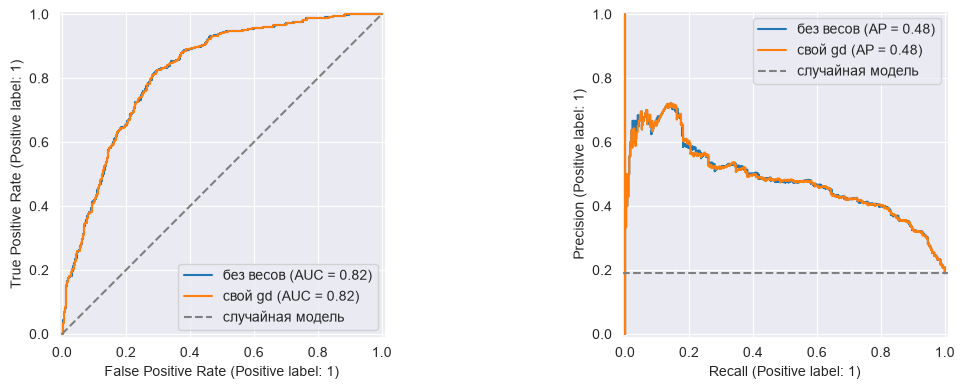

,оценки,roc_auc
0,p,0.820876
1,10p,0.820876
2,p^3,0.820876
3,logit(p),0.820876
4,-p,0.179124
5,метки 0/1,0.619333


In [14]:
# параметры gd выбираются по сходимости на train, без test
wine_gd = make_pipeline(
   StandardScaler(),
    LogReg(gd_type='full', eta=1, max_iter=10000, tolerance=1e-6),
)

wine_gd.fit(X_train, y_train)
gd_estimator = wine_gd.steps[-1][1]
print('gd:', gd_estimator.n_iter_, gd_estimator.stop_reason_)
print('изменение loss на последней итерации:',
   gd_estimator.loss_history[-1] - gd_estimator.loss_history[-2])


wine_models = {'без весов': wine_lr, 'свой gd': wine_gd}
auc_comparison = pd.DataFrame({
    name: {key: value for key, value in evaluate(model, X_test, y_test).items()
        if key in ['roc_auc', 'pr_auc']}
   for name, model in wine_models.items()
}).T
display(auc_comparison)



fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, model in wine_models.items():
    score = model.predict_proba(X_test)[:, 1]
    metrics.RocCurveDisplay.from_predictions(y_test, score, name=name, ax=axes[0])
    metrics.PrecisionRecallDisplay.from_predictions(y_test, score, name=name, ax=axes[1])

axes[0].plot([0, 1], [0, 1], '--', color='gray', label='случайная модель')
axes[1].axhline(y_test.mean(), ls='--', color='gray', label='случайная модель')
axes[0].legend()
axes[1].legend()
plt.tight_layout()
plt.show()


p = wine_lr.predict_proba(X_test)[:, 1]
p_safe = np.clip(p, 1e-15, 1 - 1e-15)
score_variants = {
    'p': p, '10p': 10 * p, 'p^3': p ** 3,
    'logit(p)': np.log(p_safe / (1 - p_safe)), '-p': -p,
    'метки 0/1': wine_lr.predict(X_test),
}

transformed_auc = pd.DataFrame([
    {'оценки': name, 'roc_auc': metrics.roc_auc_score(y_test, score)}
    for name, score in score_variants.items()
])
display(transformed_auc)

собственный gd сошелся по tolerance за 3809 итераций. sklearn немного лучше по обеим метрикам: roc-auc 0.8209 против 0.8206, pr-auc 0.4848 против 0.4838. ранжирование моделей совпадает, но разница небольшая и по одному разбиению нельзя считать ее устойчивым преимуществом

уровень случайной модели на pr-графике равен доле хороших вин, примерно 0.1898. при случайном отборе именно такая доля выбранных объектов в среднем будет положительной. поэтому здесь baseline не равен 0.5. pr-auc в таблице считается как average precision, как указано в задании

10p, p^3 и logit(p) сохраняют порядок объектов, поэтому roc-auc остается 0.8209. преобразование -p переворачивает порядок и дает 1 - auc = 0.1791

если передать метки 0/1, roc-auc вычислится, но информация о ранжировании внутри двух групп потеряется. здесь получается 0.6193. в бинарной задаче auc для таких меток равен среднему tpr и tnr, то есть balanced accuracy

### Задание 2.5. Выбор порога (0.75 балла)

Порог 0.5 у логистической регрессии ничем не выделен – его можно и нужно выбирать под задачу. Но подбирать порог на тестовой выборке нельзя: тогда оценка качества на тесте окажется завышенной.

1. Выделите из тренировочной выборки валидационную (`test_size=0.25`, `stratify`, `random_state=42`). Обучите пайплайн логистической регрессии на оставшейся части и получите вероятности на валидации.
2. Постройте на одном графике зависимость precision, recall и $F_1$ на валидации от порога $t \in [0, 1]$.
3. По валидации выберите два порога:
   - $t_{F_1}$ – максимизирующий $F_1$;
   - $t_{R}$ – дающий максимальный precision при условии recall $\ge 0.7$ (сервис хочет, чтобы в подборку попадало не меньше 70% хороших вин).
4. Переобучите пайплайн на всей тренировочной выборке и посчитайте на тестовой выборке precision, recall и $F_1$ при порогах $0.5$, $t_{F_1}$ и $t_{R}$. Сведите результаты в таблицу.

Выполнилось ли на тесте условие recall $\ge 0.7$? Почему порог, подобранный на валидации, не гарантирует выполнения условия на новых данных? Какой порог вы бы выбрали для сценария из описания данных и почему?

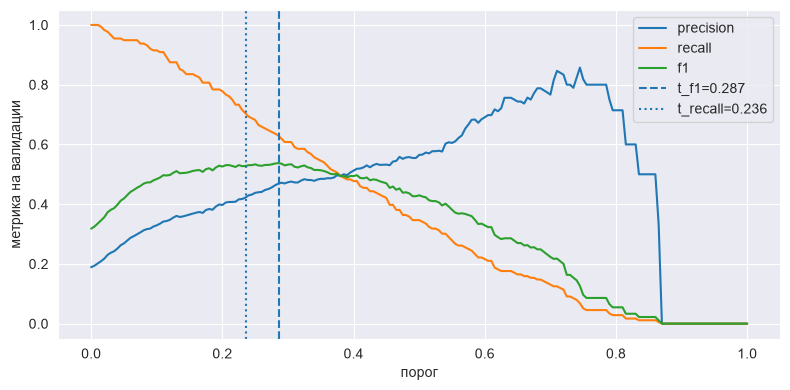

,порог,значение,precision,recall,f1
0,0.5,0.500000,0.564815,0.346591,0.429577
1,t_f1,0.286550,0.470339,0.630682,0.538835
2,t_recall,0.236359,0.426117,0.704545,0.531049


,порог,значение,precision,recall,f1
0,0.5,0.500000,0.522727,0.303630,0.384134
1,t_f1,0.286550,0.457421,0.620462,0.526611
2,t_recall,0.236359,0.421260,0.706271,0.527744


In [15]:
X_fit, X_val, y_fit, y_val = train_test_split(
   X_train, y_train, test_size=0.25, stratify=y_train, random_state=RANDOM_STATE,
)
validation_lr = clone(wine_lr).fit(X_fit, y_fit)
p_val = validation_lr.predict_proba(X_val)[:, 1]


# все различные классификации, а не только грубая сетка порогов
val_precision, val_recall, val_thresholds = metrics.precision_recall_curve(y_val, p_val)
val_precision, val_recall = val_precision[:-1], val_recall[:-1]
val_f1 = 2 * val_precision * val_recall / np.maximum(val_precision + val_recall, 1e-15)
t_f1 = float(val_thresholds[np.argmax(val_f1)])
eligible = np.flatnonzero(val_recall >= 0.7)
best_recall_index = eligible[np.argmax(val_precision[eligible])]
t_recall = float(val_thresholds[best_recall_index])



threshold_grid = np.linspace(0, 1, 201)
grid_rows = []
for threshold in threshold_grid:
    pred = p_val >= threshold
    grid_rows.append([
       metrics.precision_score(y_val, pred, zero_division=0),
        metrics.recall_score(y_val, pred, zero_division=0),
         metrics.f1_score(y_val, pred, zero_division=0),
    ])

plt.figure(figsize=(8, 4))
for j, name in enumerate(['precision', 'recall', 'f1']):
    plt.plot(threshold_grid, np.asarray(grid_rows)[:, j], label=name)

plt.axvline(t_f1, ls='--', label=f't_f1={t_f1:.3f}')
plt.axvline(t_recall, ls=':', label=f't_recall={t_recall:.3f}')
plt.xlabel('порог')
plt.ylabel('метрика на валидации')
plt.legend()
plt.tight_layout()
plt.show()


display(pd.DataFrame([
    {'порог': label, 'значение': threshold,
     **{key: value for key, value in evaluate(validation_lr, X_val, y_val, threshold).items()
        if key in ['precision', 'recall', 'f1']}}
   for label, threshold in [('0.5', 0.5), ('t_f1', t_f1), ('t_recall', t_recall)]
]))



wine_lr.fit(X_train, y_train)
threshold_test = pd.DataFrame([
    {'порог': label, 'значение': threshold,
     **{key: value for key, value in evaluate(wine_lr, X_test, y_test, threshold).items()
        if key in ['precision', 'recall', 'f1']}}
    for label, threshold in [('0.5', 0.5), ('t_f1', t_f1), ('t_recall', t_recall)]
])

display(threshold_test)

по валидации выбраны t_f1=0.2865 и t_recall=0.2364. на тесте при t_f1 получились precision=0.4574, recall=0.6205 и f1=0.5266. при t_recall - 0.4213, 0.7063 и 0.5277 соответственно. при стандартном пороге 0.5 recall был только 0.3036

условие recall >= 0.7 на тесте выполнилось для t_recall. гарантии нет: валидация и новые данные состоят из разных объектов, а после выбора порога модель еще переобучается на всем train, поэтому ее оценки могут немного сдвинуться

для исходного сценария из этих трех вариантов я бы взял t_f1 как компромисс: он отбирает меньше посредственных вин, чем t_recall, и находит заметно больше хороших, чем порог 0.5. если требование охватить минимум 70% хороших вин обязательно, нужен t_recall с дальнейшим контролем recall на новых данных. близкие f1 на тесте не использую для повторного выбора порога

## <font color="green">Часть 3. Несбалансированные классы (2.5 балла)</font>

Класс «хорошее вино» встречается примерно в 5 раз реже остальных. На семинаре 4 мы обсуждали, что с этим можно сделать:
- задать классам веса (`class_weight='balanced'`);
- сбалансировать обучающую выборку: undersampling, oversampling и их комбинации (библиотека [imbalanced-learn](https://imbalanced-learn.org/stable/)).

Во всех заданиях этой части сравнивайте модели по одному и тому же набору метрик на тестовой выборке: accuracy, precision, recall, $F_1$ (при пороге по умолчанию), ROC-AUC и PR-AUC. Удобно написать для этого одну функцию, которая принимает обученную модель и возвращает строку таблицы.

**Важно:** ресемплинг применяется **только к тренировочной выборке**. Тестовая выборка остаётся нетронутой, иначе метрики перестанут отражать качество на реальном распределении классов.

### Задание 3.1. Веса классов (0.5 балла)

Обучите логистическую регрессию в пайплайне со `StandardScaler` с параметром `class_weight=None` и `class_weight='balanced'`. Сведите метрики двух моделей в таблицу.

1. Какие веса получают объекты классов 0 и 1 при `class_weight='balanced'`? Посчитайте их по формуле из документации `sklearn`.
2. Какие метрики заметно изменились, а какие почти нет? Объясните, почему.

In [16]:
wine_balanced = make_pipeline(
   StandardScaler(), LogisticRegression(class_weight='balanced', random_state=RANDOM_STATE),
).fit(X_train, y_train)

wine_models['balanced'] = wine_balanced


class_counts = y_train.value_counts().sort_index()
class_weights = len(y_train) / (len(class_counts) * class_counts)
display(pd.DataFrame({'объекты': class_counts, 'вес': class_weights}))



balance_table = pd.DataFrame({
     name: evaluate(wine_models[name], X_test, y_test)
    for name in ['без весов', 'balanced']
}).T

display(balance_table)

,объекты,вес
target,,
0,3018,0.616965
1,706,2.637394


,accuracy,precision,recall,f1,roc_auc,pr_auc
без весов,0.815163,0.522727,0.303630,0.384134,0.820876,0.484766
balanced,0.734336,0.398660,0.785479,0.528889,0.820935,0.481147


по [формуле sklearn](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html) вес класса k равен n / (2 * n_k). для класса 0 получился вес 0.6170, для класса 1 - 2.6374. ошибка на редком классе получает больший вес

recall вырос с 0.3036 до 0.7855, а precision снизился с 0.5227 до 0.3987. f1 вырос с 0.3841 до 0.5289, accuracy снизилась с 0.8152 до 0.7343: модель стала чаще относить объекты к хорошим винам

roc-auc почти не изменился: около 0.821 у обеих моделей. pr-auc тоже близок: 0.4848 и 0.4811. веса сильно поменяли решения при пороге 0.5, но порядок объектов по оценкам изменился слабее

### Задание 3.2. Ресемплинг (1 балл)

С помощью `imblearn.pipeline.make_pipeline` соберите пайплайны логистической регрессии с разными способами балансировки:
- `RandomUnderSampler`;
- `NearMiss(version=2)`;
- `RandomOverSampler`;
- `SMOTE`.

Для каждого метода выведите размеры классов в обучающей выборке после ресемплинга и добавьте строку в таблицу метрик из задания 3.1.

Ответьте на вопросы:
- Почему здесь нужен `make_pipeline` именно из `imblearn`, а не из `sklearn`? Что произойдёт с тестовой выборкой при вызове `predict` у такого пайплайна?
- Почему нельзя сначала сбалансировать весь датасет, а уже потом разбить его на train и test?
- Какой из методов оказался лучшим по PR-AUC, а какой – худшим? Как вы думаете, почему?
- Для каких из четырёх методов важен порядок шагов «ресемплинг» и «масштабирование» в пайплайне, а для каких нет? Почему? Проверьте на одном из методов, что изменится, если поменять шаги местами.

In [17]:
from imblearn.pipeline import make_pipeline as make_imblearn_pipeline
from imblearn.under_sampling import RandomUnderSampler, NearMiss
from imblearn.over_sampling import RandomOverSampler, SMOTE


samplers = {
   'random under': RandomUnderSampler(random_state=RANDOM_STATE),
    'near miss': NearMiss(version=2),
     'random over': RandomOverSampler(random_state=RANDOM_STATE),
    'smote': SMOTE(random_state=RANDOM_STATE),
}

resampled_counts = []
for name, sampler in samplers.items():
    model = make_imblearn_pipeline(
       StandardScaler(), sampler, LogisticRegression(random_state=RANDOM_STATE),
    ).fit(X_train, y_train)
    wine_models[name] = model
    # повторяем только ресемплинг на train для подсчета размеров классов
    X_scaled = model.steps[0][1].transform(X_train)
    _, y_resampled = clone(sampler).fit_resample(X_scaled, y_train)
    counts = pd.Series(y_resampled).value_counts()
    resampled_counts.append({'метод': name, 'класс 0': counts[0], 'класс 1': counts[1]})


display(pd.DataFrame(resampled_counts))

resampling_table = pd.DataFrame({
    name: evaluate(model, X_test, y_test)
    for name, model in wine_models.items() if name != 'свой gd'
}).T
display(resampling_table)



smote_before_scaler = make_imblearn_pipeline(
   SMOTE(random_state=RANDOM_STATE), StandardScaler(),
    LogisticRegression(random_state=RANDOM_STATE),
).fit(X_train, y_train)
wine_models['smote до scaler'] = smote_before_scaler


order_comparison = pd.DataFrame({
    'scaler -> smote': evaluate(wine_models['smote'], X_test, y_test),
    'smote -> scaler': evaluate(smote_before_scaler, X_test, y_test),
}).T
display(order_comparison)

,метод,класс 0,класс 1
0,random under,706,706
1,near miss,706,706
2,random over,3018,3018
3,smote,3018,3018


,accuracy,precision,recall,f1,roc_auc,pr_auc
без весов,0.815163,0.522727,0.303630,0.384134,0.820876,0.484766
balanced,0.734336,0.398660,0.785479,0.528889,0.820935,0.481147
random under,0.733083,0.395939,0.772277,0.523490,0.820628,0.479891
near miss,0.646617,0.329412,0.831683,0.471910,0.786523,0.447903
random over,0.733083,0.398010,0.792079,0.529801,0.821108,0.481077
smote,0.734962,0.397611,0.768977,0.524184,0.819595,0.479606


,accuracy,precision,recall,f1,roc_auc,pr_auc
scaler -> smote,0.734962,0.397611,0.768977,0.524184,0.819595,0.479606
smote -> scaler,0.739348,0.402418,0.768977,0.528345,0.821629,0.485152


после random under и near miss осталось по 706 объектов каждого класса. после random over и smote стало по 3018 объектов каждого класса

нужен пайплайн из imblearn, потому что sampler меняет число строк X и y через fit_resample. обычный sklearn-пайплайн рассчитан на преобразования признаков с сохранением соответствия строк. при predict sampler пропускается, тест только масштабируется и передается классификатору

балансировать весь датасет до split нельзя: повторные или синтетически связанные объекты могут попасть в обе части, а распределение классов теста перестанет отражать исходную задачу

среди четырех методов лучший pr-auc у random over: 0.4811, худший у near miss: 0.4479. random over сохраняет все исходные объекты, а near miss оставляет только выбранную по расстояниям часть большинства и может сильно изменить его распределение. в этом эксперименте балансировка не дала заметного выигрыша по ранжированию

для near miss и smote масштабирование меняет соседей, поэтому меняется и результат ресемплинга. для случайных under/over выбор индексов от масштаба не зависит. но весь пайплайн все равно может отличаться: scaler после sampler обучается на другом распределении, что влияет на регуляризованный классификатор

у smote перестановка шагов действительно изменила метрики: pr-auc вырос с 0.4796 до 0.4852, f1 - с 0.5242 до 0.5283. это сравнение фиксированных вариантов на тесте, итоговый вариант выбираю отдельно по валидации

### Задание 3.3. Веса классов или порог? (0.75 балла)

Сравните на тестовой выборке две модели:
- логистическую регрессию с `class_weight='balanced'` и порогом 0.5;
- логистическую регрессию без весов с порогом $t_{F_1}$ из задания 2.5.

Постройте их PR-кривые на одном графике и отметьте на каждой кривой точку, соответствующую выбранному порогу. Сильно ли различаются кривые? Можно ли сказать, что взвешивание классов в основном «сдвигает порог»?

,accuracy,precision,recall,f1,roc_auc,pr_auc
"balanced, t=0.5",0.734336,0.398660,0.785479,0.528889,0.820935,0.481147
"без весов, t_f1",0.788221,0.457421,0.620462,0.526611,0.820876,0.484766


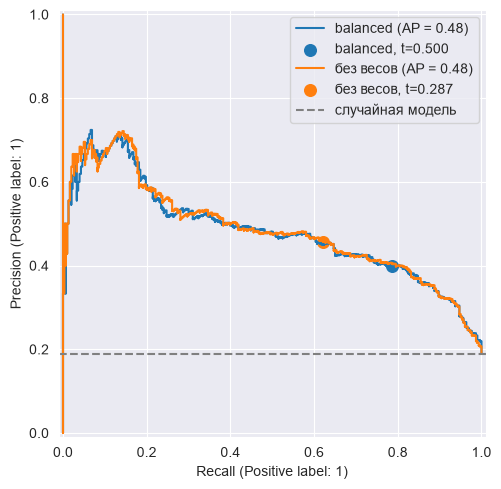

In [18]:
weight_threshold_comparison = pd.DataFrame({
   'balanced, t=0.5': evaluate(wine_balanced, X_test, y_test),
     'без весов, t_f1': evaluate(wine_lr, X_test, y_test, t_f1),
}).T


display(weight_threshold_comparison)

fig, ax = plt.subplots(figsize=(7, 5))
for name, model, threshold in [
    ('balanced', wine_balanced, 0.5), ('без весов', wine_lr, t_f1),
]:
    score = model.predict_proba(X_test)[:, 1]
    metrics.PrecisionRecallDisplay.from_predictions(y_test, score, name=name, ax=ax)
    pred = score >= threshold
    ax.scatter(metrics.recall_score(y_test, pred),
            metrics.precision_score(y_test, pred, zero_division=0),
             s=70, label=f'{name}, t={threshold:.3f}')


ax.axhline(y_test.mean(), color='gray', ls='--', label='случайная модель')
ax.legend()
plt.tight_layout()
plt.show()

pr-кривые близки: pr-auc равен 0.4811 у balanced и 0.4848 у модели без весов. но выбранные рабочие точки различаются. balanced с порогом 0.5 дает precision=0.3987 и recall=0.7855, а модель без весов с t_f1 - 0.4574 и 0.6205

в этом эксперименте взвешивание в основном меняет рабочую точку: при пороге 0.5 модель начинает чаще выбирать хороший класс. это похоже на снижение порога у обычной модели. точного равенства нет, потому что при взвешивании переобучаются все коэффициенты, поэтому ранжирование тоже немного меняется

### Задание 3.4. Итоги (0.25 балла)

Сведите в одну таблицу все модели частей 2 и 3 (метрики на тестовой выборке). Какую модель и какой порог вы бы предложили сервису из сценария? Обоснуйте выбор, опираясь на метрики.

In [19]:
# выбор для сервиса: максимум f1 на валидации, при равенстве выше precision
# свой gd оставляем учебным ориентиром; для приложения берем готовый sklearn-пайплайн
selection_rows = []
for name, model in wine_models.items():
    if name == 'свой gd':
        continue
    candidate = clone(model).fit(X_fit, y_fit)
    scores = candidate.predict_proba(X_val)[:, 1]
    precision, recall, thresholds = metrics.precision_recall_curve(y_val, scores)
    precision, recall = precision[:-1], recall[:-1]
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-15)
    threshold = float(thresholds[np.argmax(f1)])
    selection_rows.append({
       'модель': name, 'порог': threshold,
         **evaluate(candidate, X_val, y_val, threshold),
    })


validation_selection = pd.DataFrame(selection_rows).sort_values(
   ['f1', 'precision'], ascending=False, kind='stable',
).reset_index(drop=True)

print('выбор только по валидации:')
display(validation_selection)



final_name = validation_selection.loc[0, 'модель']
final_threshold = float(validation_selection.loc[0, 'порог'])
final_model = clone(wine_models[final_name]).fit(X_train, y_train)


all_rows = [{
    'модель': 'всегда 0', 'порог': 0.5, 'accuracy': constant_accuracy,
    'precision': 0.0, 'recall': 0.0, 'f1': 0.0,
    'roc_auc': 0.5, 'pr_auc': y_test.mean(),
}]
for name, model in wine_models.items():
    all_rows.append({'модель': name, 'порог': 0.5, **evaluate(model, X_test, y_test)})
for name, threshold in [('без весов, t_f1', t_f1), ('без весов, t_recall', t_recall)]:
    all_rows.append({'модель': name, 'порог': threshold,
                 **evaluate(wine_lr, X_test, y_test, threshold)})
all_rows.append({'модель': f'итоговая: {final_name}', 'порог': final_threshold,
              **evaluate(final_model, X_test, y_test, final_threshold)})

all_test_metrics = pd.DataFrame(all_rows)
print('финальная оценка на test:')
display(all_test_metrics)
print(f'для сервиса: {final_name}, порог={final_threshold:.4f}')

выбор только по валидации:


,модель,порог,accuracy,precision,recall,f1,roc_auc,pr_auc
0,smote до scaler,0.579564,0.777658,0.445614,0.721591,0.550976,0.825090,0.526899
1,balanced,0.579058,0.776584,0.443662,0.715909,0.547826,0.824308,0.522796
2,smote,0.570050,0.770140,0.434932,0.721591,0.542735,0.822629,0.525680
3,random over,0.575971,0.773362,0.438596,0.710227,0.542299,0.824262,0.529602
4,random under,0.562807,0.763695,0.427152,0.732955,0.539749,0.825331,0.522514
5,без весов,0.286550,0.795918,0.470339,0.630682,0.538835,0.824285,0.523514
6,near miss,0.746735,0.771214,0.426877,0.613636,0.503497,0.786326,0.478929


финальная оценка на test:


,модель,порог,accuracy,precision,recall,f1,roc_auc,pr_auc
0,всегда 0,0.500000,0.810150,0.000000,0.000000,0.000000,0.500000,0.189850
1,без весов,0.500000,0.815163,0.522727,0.303630,0.384134,0.820876,0.484766
2,свой gd,0.500000,0.814536,0.520000,0.300330,0.380753,0.820562,0.483764
3,balanced,0.500000,0.734336,0.398660,0.785479,0.528889,0.820935,0.481147
4,random under,0.500000,0.733083,0.395939,0.772277,0.523490,0.820628,0.479891
5,near miss,0.500000,0.646617,0.329412,0.831683,0.471910,0.786523,0.447903
6,random over,0.500000,0.733083,0.398010,0.792079,0.529801,0.821108,0.481077
7,smote,0.500000,0.734962,0.397611,0.768977,0.524184,0.819595,0.479606
8,smote до scaler,0.500000,0.739348,0.402418,0.768977,0.528345,0.821629,0.485152
9,"без весов, t_f1",0.286550,0.788221,0.457421,0.620462,0.526611,0.820876,0.484766


для сервиса: smote до scaler, порог=0.5796


для сервиса выбрал пайплайн smote -> scaler -> logistic regression с порогом 0.5796. критерий выбора задан до сравнения кандидатов: максимальный f1 на валидации, при равенстве выше precision. свой gd использую как учебный ориентир, а для приложения выбираю готовый sklearn-пайплайн

на валидации у этого варианта f1=0.5510, precision=0.4456, recall=0.7216. после выбора пайплайн переобучен на всем train. на тесте получились f1=0.5287, precision=0.4313, recall=0.6832, roc-auc=0.8216 и pr-auc=0.4852

это компромисс между качеством подборки и охватом: модель находит около 68% хороших вин, но среди рекомендаций хорошими являются только около 43%. качество пока умеренное, обещать клиентам безошибочный отбор нельзя. для требования recall >= 0.7 этот итоговый вариант на тесте не прошел порог, хотя на валидации проходил

преимущество по валидации над balanced небольшое, поэтому победу нельзя считать устойчивой без дополнительных разбиений. тестовые числа нужны для финальной оценки и не использовались для смены модели или порога. таблица выше объединяет все модели и варианты порогов частей 2 и 3

### Сохранение модели (0 баллов, нужно для части 4)

Сохраните итоговую модель (весь пайплайн, а не только `LogisticRegression`), выбранный порог и тестовую выборку – они понадобятся в приложении. Допишите ячейку под свою итоговую модель.

Если работаете в Colab, скачайте папку `wine_app/` на свой компьютер (например, заархивируйте её и воспользуйтесь `google.colab.files.download`): приложение запускается локально.

In [20]:
import json
import joblib


app_dir = Path('wine_app')
app_dir.mkdir(exist_ok=True)
joblib.dump(final_model, app_dir / 'model.joblib')
(app_dir / 'config.json').write_text(
   json.dumps({'threshold': final_threshold}, indent=2), encoding='utf-8',
)
X_test.assign(target=y_test).to_csv(app_dir / 'test.csv', index=False)



# проверяем сохранение всего пайплайна, включая масштабирование
loaded_model = joblib.load(app_dir / 'model.joblib')
assert np.allclose(loaded_model.predict_proba(X_test), final_model.predict_proba(X_test))
assert json.loads((app_dir / 'config.json').read_text())['threshold'] == final_threshold

print('сохранены:', ', '.join(path.name for path in sorted(app_dir.iterdir())))
print('загрузка модели проверена, вероятности совпадают')

сохранены: README.md, app.py, config.json, model.joblib, requirements.txt, test.csv
загрузка модели проверена, вероятности совпадают


## <font color="green">Часть 4. Демо-приложение на Streamlit (2.5 балла)</font>

Модель в ноутбуке видите только вы. Чтобы ей мог пользоваться сомелье сервиса (и чтобы он понимал, почему меняется подборка при изменении порога), сделаем небольшое веб-приложение.

[Streamlit](https://docs.streamlit.io/) это библиотека, которая которая превращает обычный Python-скрипт в веб-страницу: каждый вызов вроде `st.slider(...)` или `st.write(...)` рисует элемент интерфейса, а при любом действии пользователя скрипт перезапускается сверху вниз. Минимальный пример:

```python
import streamlit as st

t = st.slider('Порог', 0.0, 1.0, 0.5)
st.write('Вы выбрали порог', t)
```

Приложение запускается **локально**, а не в Colab:

```bash
pip install streamlit
streamlit run app.py
```

Полезные элементы: [`st.number_input`](https://docs.streamlit.io/develop/api-reference/widgets/st.number_input), [`st.slider`](https://docs.streamlit.io/develop/api-reference/widgets/st.slider), [`st.tabs`](https://docs.streamlit.io/develop/api-reference/layout/st.tabs), [`st.file_uploader`](https://docs.streamlit.io/develop/api-reference/widgets/st.file_uploader), [`st.download_button`](https://docs.streamlit.io/develop/api-reference/widgets/st.download_button), [`st.pyplot`](https://docs.streamlit.io/develop/api-reference/charts/st.pyplot), [`st.metric`](https://docs.streamlit.io/develop/api-reference/data/st.metric), [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource) (чтобы не загружать модель заново при каждом перезапуске скрипта).

Приложение `wine_app/app.py` использует файлы, сохранённые в ячейке выше (`model.joblib`, `config.json`, `test.csv`). **Модель внутри приложения не обучается.**

### Задание 4.1. Оценка одного вина (0.5 балла)

Сделайте вкладку, на которой пользователь вводит 12 признаков вина (диапазоны и значения по умолчанию возьмите из данных, например минимум, максимум и медиану по `test.csv`; признак `is_red` – переключатель «красное / белое»). Сделайте сайдбар с интерактивным ползунком значения порога, установите порог по умолчанию значением из файла `config.json`. Приложение показывает вероятность того, что вино хорошее, и решение модели при установленном пороге.

### Задание 4.2. Интерактивная визуализация модельных метрик (0.5 балла)

Сделайте вкладку «Модельные метрики». При изменении порога на тестовой выборке пересчитываются и выводятся:
- матрица ошибок;
- precision, recall и $F_1$;
- ROC- и PR-кривые, на которых отмечена точка, соответствующая текущему порогу.

Добавьте короткий текст для сомелье: что произойдёт с подборкой, если порог увеличить или уменьшить.

### Задание 4.3. Пакетное предсказание (0.5 балла)

Сделайте вкладку, на которой пользователь загружает CSV-файл с признаками вин (без столбца `target`), а приложение показывает таблицу с вероятностью и решением для каждого вина и даёт скачать её через `st.download_button`. Порог для этой вкладки берётся из слайдера задания 4.2 (подсказка: [`st.session_state`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.session_state)) или задаётся отдельно – на ваш выбор.

Приложение не должно падать, если в файле не хватает столбцов: в этом случае выведите понятное сообщение об ошибке (`st.error`).

### Задание 4.4. Что выучила модель (0.25 балла)

Сделайте вкладку с горизонтальной столбчатой диаграммой коэффициентов логистической регрессии (после масштабирования признаков), отсортированных по значению. Подпишите, какие признаки сильнее всего «голосуют» за хорошее вино, а какие – против.

### Задание 4.5. Кэширование (0.25 балла)

Streamlit выполняет `app.py` заново при каждом действии пользователя: сдвинули слайдер порога – скрипт отработал сверху вниз ещё раз. Без кэширования при каждом движении слайдера модель снова читается с диска, а вероятности на тестовой выборке пересчитываются, хотя от порога они не зависят.

1. Модель загружается функцией с декоратором [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource): один объект на весь сервер. Путь к файлу строится от папки, где лежит `app.py` (`Path(__file__).parent`), а не от текущей директории.
2. `test.csv` читается функцией с декоратором [`st.cache_data`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_data).
3. Вероятности класса 1 на тестовой выборке считаются один раз, в функции с `st.cache_data`. При движении слайдера в задании 4.2 меняется только сравнение с порогом, `predict_proba` заново не вызывается. Подсказка: аргумент, который Streamlit не должен хешировать (например, модель), называют с подчёркиванием в начале: `def test_proba(_model, X): ...`.

Ответьте в `README.md` или в комментарии в `app.py`: почему для модели используется `st.cache_resource`, а для таблиц – `st.cache_data`? Что изменится, если вызвать `joblib.load` без декоратора?

Использование `joblib.load` без декоратора или загрузка модели через `st.cache_data` за этот пункт не засчитываются.

### Задание 4.6. Оформление и сдача (0.5 балла)

1. Сдайте папку `wine_app/` (архивом или укажите в клетке ниже ссылку на Github репозиторий) со следующим содержимым:
- `app.py`;
- `model.joblib`, `config.json`, `test.csv`;
- `requirements.txt` с версиями библиотек, при которых приложение запускается;
- `README.md`: инструкция о том, как запустить приложение с указанием версии Python интерпретатора.

2. Проведите деплой приложения на [Streamlit Community Cloud](https://streamlit.io/cloud).

демо-приложение: [открыть сайт](https://mmadhw3-cgrmqnwypngrcsngph9om9.streamlit.app/)

файлы приложения: [MMAD_HW3](https://github.com/LeskaProgrammer/MMAD_HW3)

код приложения находится в папке `wine_app/`, запуск описан в `wine_app/README.md`

**Опишите общие мысли о работе. Это место для вашей рефлексии – необязательное, но полезное.** 🍷